# 6.1 · 回测引擎基础：目标权重 → 净值

> **回测（backtest）**：用历史数据模拟"如果过去按这个策略交易，会赚多少、亏多少"。
> 回测是检验策略的关键环节，但也是最容易"自欺欺人"的地方。本节先搞懂回测引擎的基本原理和绩效指标。

## 一、回测引擎的两种实现

| 类型 | 做法 | 特点 |
|---|---|---|
| **事件驱动** | 逐根 K 线、逐笔订单、撮合、更新账户 | 最贴近真实，支持复杂逻辑，但慢 |
| **向量化** | 用矩阵运算一次性算出收益 | 快、简洁，适合选股策略 |

事件驱动的核心组件：**事件（行情）→ 策略（信号）→ 订单 → 撮合 → 账户（现金/持仓/净值）**。
本节用向量化引擎（选股足够），并讲清账户净值的计算逻辑。

## 二、关键：避免未来函数

回测的生命线——**在 T 日做决策时，只能用到 T 日及之前的数据**。
- 信号在 T 日收盘生成，T+1 才持有；
- 向量化实现：用 `weights.shift(1)`（昨日权重 × 今日收益），保证不会"用今天的权重吃今天的收益"。

> 一旦用到未来数据（未来函数 / look-ahead bias），回测收益会虚高，实盘必然失败。

## 三、构造目标权重并回测（代码在 backtest_lab.engine）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from backtest_lab.engine import run_backtest, performance_summary
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
sp = facs['SMB 小市值']
W = pd.DataFrame(0.0, index=sp.index, columns=sp.columns)
for dt in sp.index:
    top = sp.loc[dt].dropna().nlargest(30)
    W.loc[dt, top.index] = 1.0/30
W = W.loc['2023-01-01':]; c = close.loc[W.index]
bt0 = run_backtest(W, c, cost_bps=0)
bt1 = run_backtest(W, c, cost_bps=20)
print('日均双边换手 %.3f，年化交易成本 %.1f%%' %
      (bt1['turnover'].mean(), bt1['cost'].mean()*242*100))

[17084:MainThread](2026-10-30 01:44:32,776) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[17084:MainThread](2026-10-30 01:44:34,234) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[17084:MainThread](2026-10-30 01:44:34,235) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


日均双边换手 0.062，年化交易成本 3.0%


## 四、净值与绩效指标

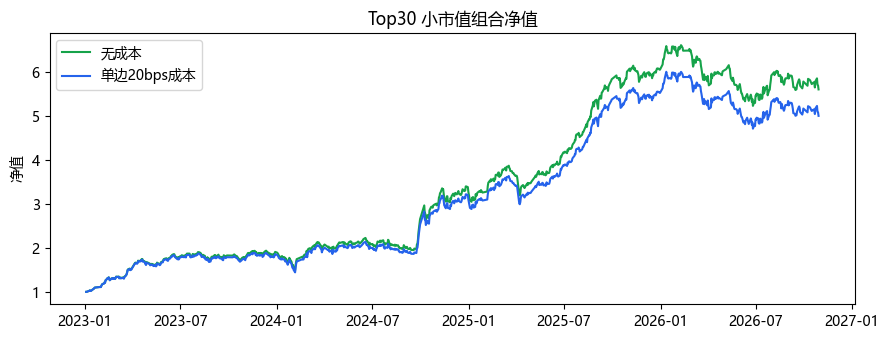

          无成本  20bps成本
年化收益    0.571    0.525
年化波动    0.264    0.264
夏普      2.163    1.990
最大回撤   -0.231   -0.235
Calmar  2.476    2.234
胜率      0.541    0.537


In [2]:
plt.figure(figsize=(9, 3.5))
plt.plot(bt0['nav'], label='无成本', color='#16a34a')
plt.plot(bt1['nav'], label='单边20bps成本', color='#2563eb')
plt.title('Top30 小市值组合净值'); plt.ylabel('净值'); plt.legend()
plt.tight_layout(); plt.show()

cmp = pd.DataFrame({'无成本': performance_summary(bt0['return']),
                    '20bps成本': performance_summary(bt1['return'])})
print(cmp.round(3))

## 五、绩效指标解读

- **年化收益**：把区间收益换算成一年；
- **年化波动**：日收益标准差 × √242；
- **夏普**：单位总风险的超额收益；
- **最大回撤**：从最高点到最低点的最大跌幅（衡量"拿不拿得住"）；
- **Calmar**：年化收益 / 最大回撤；
- **胜率**：收益为正的天数比例。

> 成本使年化收益下降（57%→52%），换手越高的策略成本侵蚀越严重。

## 六、小结与面试要点

- 回测分事件驱动和向量化；事件驱动含事件/订单/撮合/账户，向量化用矩阵快速计算。
- 必须避免未来函数：T 日信号 T+1 持有（shift）。
- 目标权重 → 收益/净值/换手/成本；绩效看年化、夏普、回撤、Calmar、胜率。

**面试高频：**
- 回测引擎怎么实现？（答：事件驱动逐笔撮合，或向量化矩阵运算）
- 什么是未来函数？怎么避免？（答：用了未来数据；严格按时间、shift、T+1 成交）
- 回测里换手和成本怎么算？（答：权重变化 L1 × 单边费率）

## 动手练习
1. 把 Top30 改成每日/每周调仓，对比换手和成本；
2. 计算相对沪深300 的信息比率；
3. 故意用 weights（不 shift）算收益，看虚高多少，理解未来函数。

---
下一节 **6.2 交易成本与滑点：佣金、印花税、冲击成本**。